# AAVAIL Revenue Forecast | 02 - Model Comparison vs Baseline

Four models are compared for each time series using a **time-ordered hold-out
set** (the last 20% of days) and grid search with `TimeSeriesSplit`:

| model | description |
|---|---|
| baseline | `DummyRegressor` - always predicts the training mean |
| linear | Ridge regression |
| random_forest | Random forest regressor |
| gradient_boosting | Gradient boosting regressor |

The same code (`model.compare_models`) is used by `model.py` when training
production models, so this notebook reflects exactly what gets deployed.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
FIG_DIR = os.path.join('..', 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
%matplotlib inline

In [2]:
from cslib import fetch_ts, engineer_features, DATA_DIR
from model import compare_models
ts = fetch_ts(DATA_DIR)
X, y, dates = engineer_features(ts['all'], training=True)
print(X.shape)
X.head()

(581, 7)


,previous_7,previous_14,previous_28,previous_70,previous_year,recent_invoices,recent_views
0,0.00,0.00,0.00,0.00,0.0,0.000000,0.000000
1,739.97,739.97,739.97,739.97,0.0,41.000000,2276.000000
2,1237.02,1237.02,1237.02,1237.02,0.0,37.000000,2053.000000
3,2003.09,2003.09,2003.09,2003.09,0.0,39.333333,2225.666667
4,2567.69,2567.69,2567.69,2567.69,0.0,39.000000,2144.250000


## 1. Compare models on all countries combined

In [3]:
results, fitted = compare_models(X, y)
results

,model,rmse,mae,best_params
0,random_forest,1030.688338,838.853876,"{'reg__max_depth': None, 'reg__n_estimators': ..."
1,gradient_boosting,1036.934958,814.681954,"{'reg__learning_rate': 0.1, 'reg__n_estimators..."
2,linear,1320.042500,1069.809568,{'reg__alpha': 10.0}
3,baseline,2967.070381,2840.147338,{}


## 2. Visual comparison against the baseline (RMSE)

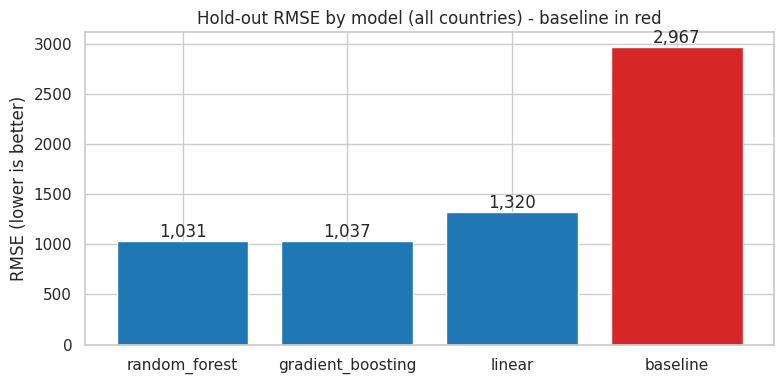

In [4]:
colors = ['tab:red' if m == 'baseline' else 'tab:blue' for m in results['model']]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(results['model'], results['rmse'], color=colors)
for i, v in enumerate(results['rmse']):
    ax.text(i, v, f'{v:,.0f}', ha='center', va='bottom')
ax.set_title('Hold-out RMSE by model (all countries) - baseline in red')
ax.set_ylabel('RMSE (lower is better)')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'model_vs_baseline_rmse.png'), dpi=120)
plt.show()

## 3. Predictions vs actual on the hold-out period

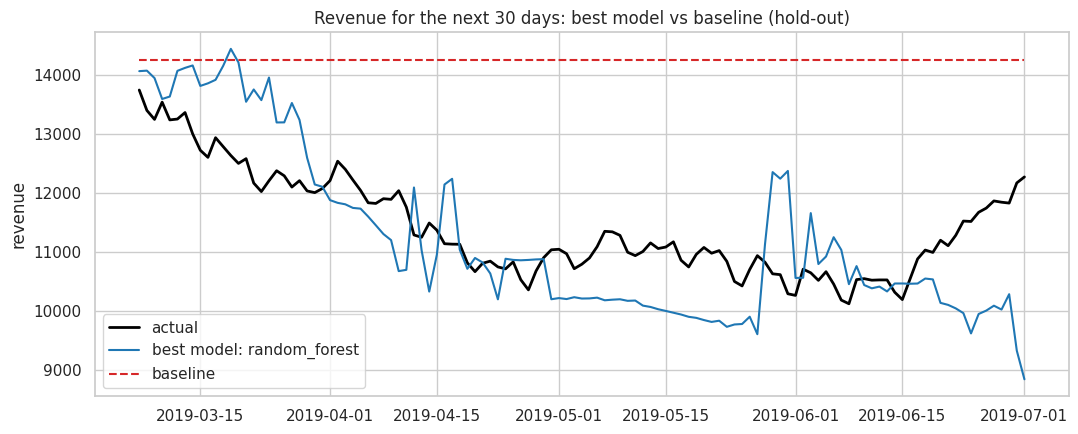

In [5]:
split = int(len(X) * 0.8)
X_test, y_test, d_test = X.iloc[split:], y[split:], dates[split:]
best_name = results.loc[0, 'model']
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(d_test, y_test, color='black', lw=2, label='actual')
ax.plot(d_test, fitted[best_name].predict(X_test), color='tab:blue', label=f'best model: {best_name}')
ax.plot(d_test, fitted['baseline'].predict(X_test), color='tab:red', ls='--', label='baseline')
ax.set_title('Revenue for the next 30 days: best model vs baseline (hold-out)')
ax.set_ylabel('revenue'); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'model_vs_baseline_holdout.png'), dpi=120)
plt.show()

## 4. Improvement over the baseline for every country

Read from `models/model_comparison.csv`, written by `python model.py`.

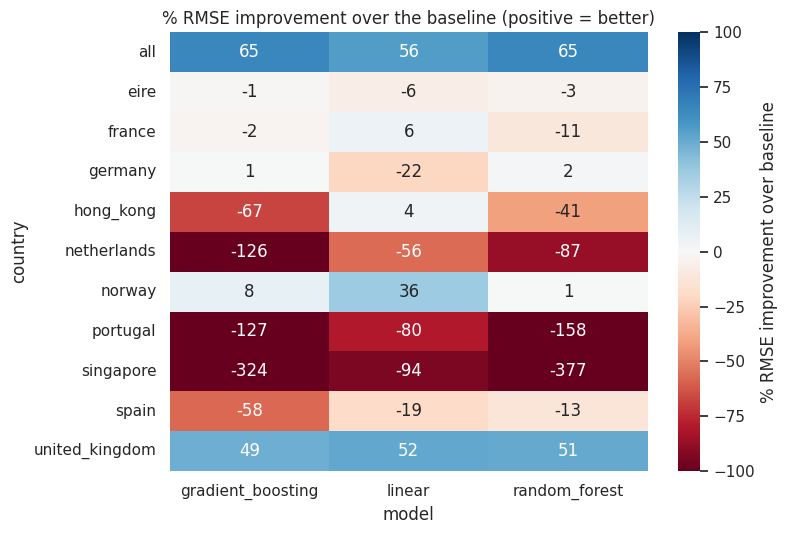

,model,rmse
country,,
all,random_forest,1030.688338
eire,baseline,234.530731
france,linear,113.489928
germany,random_forest,186.751167
hong_kong,linear,90.620290
netherlands,baseline,70.452907
norway,linear,108.075114
portugal,baseline,78.452813
singapore,baseline,40.734055


In [6]:
comp = pd.read_csv(os.path.join('..', 'models', 'model_comparison.csv'))
pivot = comp.pivot(index='country', columns='model', values='rmse')
improvement = (1 - pivot.div(pivot['baseline'], axis=0)).drop(columns='baseline') * 100
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(improvement, annot=True, fmt='.0f', cmap='RdBu', center=0, vmin=-100, vmax=100, ax=ax,
            cbar_kws={'label': '% RMSE improvement over baseline'})
ax.set_title('% RMSE improvement over the baseline (positive = better)')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'model_vs_baseline_by_country.png'), dpi=120)
plt.show()
comp.sort_values('rmse').groupby('country').first()[['model', 'rmse']]

## 5. Conclusions

* For all countries combined and for the largest country, the tree-based /
  linear models clearly beat the baseline; this supports the hypothesis from
  the EDA.
* For small countries with very noisy revenue, the baseline is sometimes the
  best choice. Because `model.py` always selects the model with the lowest
  hold-out RMSE, the deployed model for those countries is never worse than
  the baseline.
* Post-production, `monitoring.py` checks for data drift and compares the
  production RMSE with the training RMSE and the baseline.